# Age-Group Classification from Face Images (CNN)

Setup and Import libraries

In [3]:
!pip install --upgrade --quiet keras-hub keras

In [4]:
import os
import shutil
import kagglehub
import keras
import keras_hub
import tensorflow as tf

# Download the Dataset from Kaggle

In [5]:
# Download latest version
path = kagglehub.dataset_download("trainingdatapro/age-detection-human-faces-18-60-years")

print("Path to dataset files:", path)

100%|██████████| 337M/337M [00:02<00:00, 150MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/trainingdatapro/age-detection-human-faces-18-60-years/versions/1


In [6]:
# download dataset to colab
!kaggle datasets download -d trainingdatapro/age-detection-human-faces-18-60-years

Dataset URL: https://www.kaggle.com/datasets/trainingdatapro/age-detection-human-faces-18-60-years
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 337M/337M [00:02<00:00, 165MB/s]



In [7]:
# Unzip dataset
!unzip '/content/age-detection-human-faces-18-60-years.zip'

Archive:  /content/age-detection-human-faces-18-60-years.zip
  inflating: age_detection.csv       
  inflating: test/18-20/25.jpg       
  inflating: test/18-20/26.jpg       
  inflating: test/18-20/27.jpg       
  inflating: test/18-20/28.jpg       
  inflating: test/18-20/29.jpg       
  inflating: test/21-30/25.jpg       
  inflating: test/21-30/26.jpg       
  inflating: test/21-30/27.jpg       
  inflating: test/21-30/28.jpg       
  inflating: test/21-30/29.jpg       
  inflating: test/31-40/25.jpg       
  inflating: test/31-40/26.jpg       
  inflating: test/31-40/27.jpg       
  inflating: test/31-40/28.jpg       
  inflating: test/31-40/29.jpg       
  inflating: test/41-50/25.jpg       
  inflating: test/41-50/26.jpg       
  inflating: test/41-50/27.jpg       
  inflating: test/41-50/28.jpg       
  inflating: test/41-50/29.jpg       
  inflating: test/51-60/25.jpg       
  inflating: test/51-60/26.jpg       
  inflating: test/51-60/27.jpg       
  inflating: test/51-60/28.

In [8]:
# Define the dataset directory
dataset_test = '/content/test'
dataset_train = '/content/train'

In [9]:
# Training + validation datasets
train_ds, val_ds = keras.utils.image_dataset_from_directory(
    directory = dataset_train,
    labels="inferred",
    label_mode="categorical",
    batch_size=16,
    image_size=(224,224),
    shuffle=True,
    seed=42,
    subset="both",
    validation_split=0.2,
  )
# Test dataset
test_ds = keras.utils.image_dataset_from_directory(
    directory = dataset_test,
    labels="inferred",
    label_mode="categorical",
    batch_size=16,
    image_size=(224,224),
  )

Found 125 files belonging to 5 classes.
Using 100 files for training.
Using 25 files for validation.
Found 25 files belonging to 5 classes.


In [10]:
print("Class Names:", train_ds.class_names)
print("Number of Classes:", len(train_ds.class_names))

Class Names: ['18-20', '21-30', '31-40', '41-50', '51-60']
Number of Classes: 5


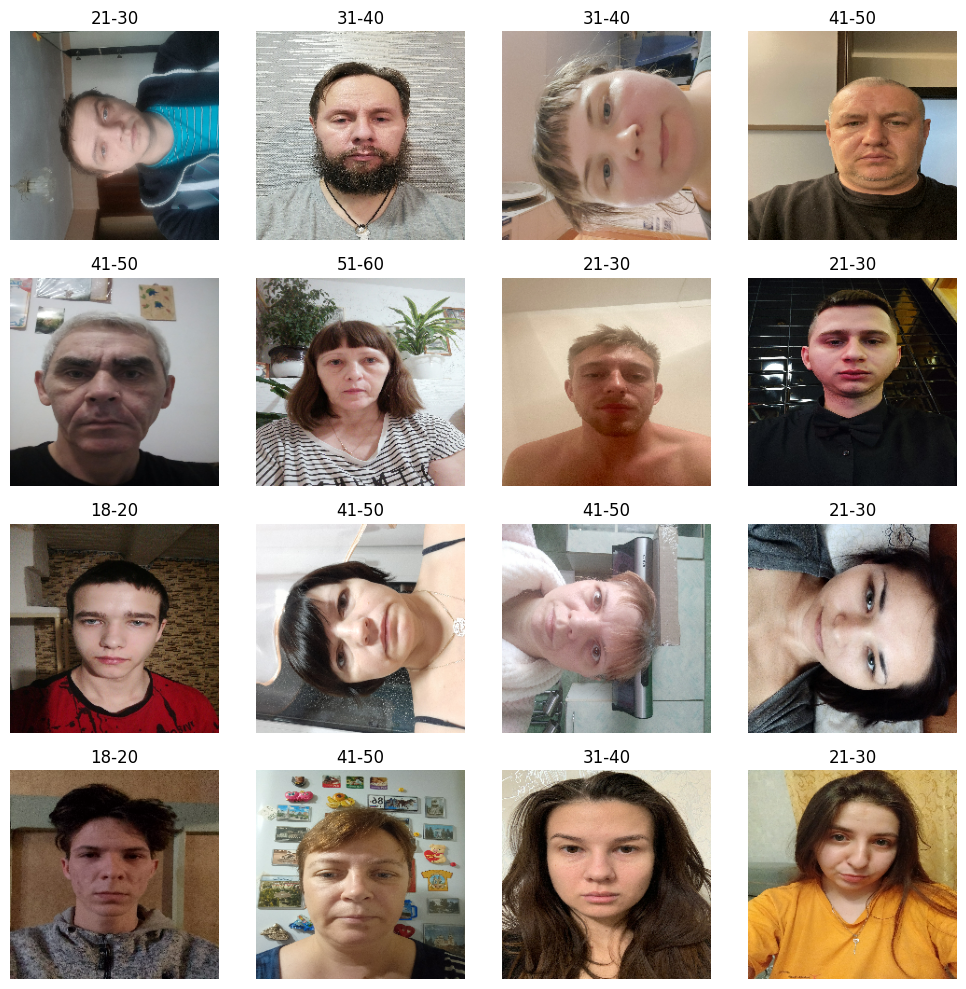

In [14]:
import numpy as np
import matplotlib.pyplot as plt

classes = train_ds.class_names
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 10))

for i, (img, label) in enumerate(zip(images[:16], labels[:16])):
    plt.subplot(4, 4, i + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.title(classes[np.argmax(label)])
    plt.axis("off")

plt.tight_layout()
plt.show()

Building Model

In [13]:
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense,Input,BatchNormalization,Dropout

In [23]:
model= Sequential()
model.add(Input((224,224,3)))

# Data augmentation
model.add(keras.layers.RandomRotation(0.1))
model.add(keras.layers.RandomZoom(0.1))
model.add(keras.layers.Rescaling(1./255))

# CNN Layers
model.add(Conv2D(filters=128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2))


model.add(Conv2D(filters=256,kernel_size=(3,3),strides=1,padding='valid',activation ='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2))


model.add(Conv2D(filters=512,kernel_size=(3,3),strides=1,padding='valid',activation='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2))


# Classification Layers
model.add(Flatten())

model.add(Dense(units=256,activation='relu'))
model.add(Dense(units=128,activation='relu'))
model.add(Dense(units=64,activation='relu'))


# Output layer
model.add(Dense(units=5,activation='softmax'))

In [24]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 128)  │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 256)  │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 346112)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │    88,604,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,125,317 (343.80 MB)

 Trainable params: 90,125,317 (343.80 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Model Compilation
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=["accuracy"])

In [26]:
# from keras.callbacks import ModelCheckpoint

# # Model checkpoint to save the best model
# checkpoint = ModelCheckpoint(
#     "best_model.keras",      # File path to save the model
#     monitor="val_accuracy", # save the model with the best validation accuracy
#     save_best_only=True,
#     verbose=1
# )

In [28]:
history = model.fit(train_ds, validation_data=val_ds, epochs=50, verbose=1)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8900 - loss: 0.3350 - val_accuracy: 0.1600 - val_loss: 5.2470
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 776ms/step - accuracy: 0.8700 - loss: 0.3919 - val_accuracy: 0.1200 - val_loss: 6.1396
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 993ms/step - accuracy: 0.8900 - loss: 0.2556 - val_accuracy: 0.0800 - val_loss: 7.1488
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 786ms/step - accuracy: 0.9300 - loss: 0.2255 - val_accuracy: 0.1200 - val_loss: 7.7261
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 866ms/step - accuracy: 0.9300 - loss: 0.1886 - val_accuracy: 0.1600 - val_loss: 7.8193
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 971ms/step - accuracy: 0.8600 - loss: 0.4658 - val_accuracy: 0.0800 - val_loss: 7.6632
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 774ms/step - accuracy: 0.9400 - loss: 0.1962 - val_accuracy: 0.1600 - val_loss: 6.5973
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 878ms/step - accuracy: 0.9500 - loss: 0.1891 - val_accuracy: 0.2000 - val_loss:

# Evaluation

In [29]:
# Evaluate model on test data
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 393ms/step - accuracy: 0.3600 - loss: 4.5500
Test Loss: 4.550012111663818
Test Accuracy: 0.36000001430511475


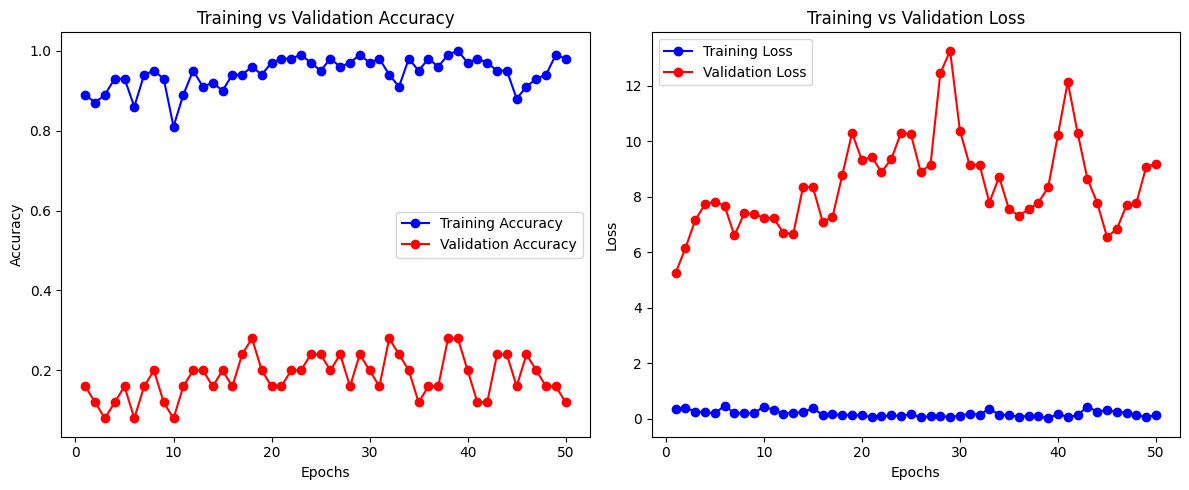

In [30]:
# Training and Validation Performance Visualization
acc = history.history['accuracy']
loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

# Number of epochs
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'ro-', label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'bo-', label='Training Loss')
plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

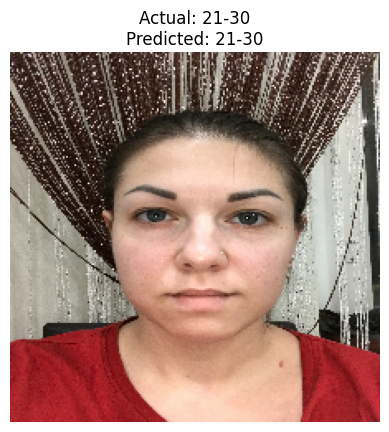

In [55]:
#  Get one batch of test images
images, labels = next(iter(test_ds))

# Predict
predictions = model.predict(images, verbose=0)

# Get class names
class_names = train_ds.class_names

# Get actual and predicted labels
actual_label = class_names[np.argmax(labels[0])]
predicted_label = class_names[np.argmax(predictions[0])]

# Display image
plt.imshow(images[0].numpy().astype("uint8"))
plt.title(f"Actual: {actual_label}\nPredicted: {predicted_label}")
plt.axis("off")
plt.show()